# 03 — Resultados, análise de erros e demonstração

Este notebook fecha a entrega final. Nele estão o baseline neural, a comparação dos experimentos e a escolha do modelo final. O modelo final é avaliado no conjunto de **teste**, que nenhum experimento tinha visto. Depois vêm os acertos, os erros e as causas deles, e por fim a demonstração imagem → pré-processamento → modelo → resultado.

| seção | item da entrega |
|---|---|
| 1 | problema e dados |
| 2 | baseline neural |
| 3 | experimentos e escolha do modelo final |
| 4 | curvas de treinamento e validação |
| 5 | modelo final no teste: métricas de segmentação |
| 6–7 | acertos, erros e análise das causas |
| 8 | demonstração |
| 9 | conclusão e limitações |

**O que precisa para rodar:** `results/` e `manifestos/`, que estão versionados; `modelos/modelo_final.pt`, que o próprio código baixa do release v1.0 se não existir; e `amostras/`. A seção 6 roda o modelo em cenas de `data/images/test` e, sem os dados preparados, mostra as figuras já salvas. Nenhuma célula treina modelo: os 24 treinos rodaram em GPU (ver `LABORATORIO.md`), e as métricas vêm de `scripts/avaliar.py`.

In [1]:
import io
import json
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as Img, display

from xbd.config import CLASS_NAMES
from xbd.metrics import Confusao

pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
AZUL, VERMELHO, VERDE, CINZA = "#1f569e", "#b02a2a", "#22783c", "#8a8a8a"

RES = RAIZ / "results"
FIG = RAIZ / "apresentacao" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

VAL = pd.DataFrame(json.loads((RES / "avaliacao_validacao.json").read_text()))
TESTE = pd.DataFrame(json.loads((RES / "avaliacao_teste.json").read_text()))
POR_CENA = json.loads((RES / "avaliacao_teste.por_cena.json").read_text())
MANIFESTO = pd.read_csv(RAIZ / "manifestos" / "manifesto.csv", low_memory=False)

BASELINE, FINAL = "ref", "abl-lr-encoder-igual"
DANO = CLASS_NAMES[1:]


def resumo(mat) -> dict:
    """Metricas a partir de uma matriz 5x5 (linha = verdade, coluna = predito)."""
    c = Confusao(5)
    c.mat = torch.as_tensor(np.asarray(mat).reshape(5, 5), dtype=torch.int64)
    return c.resumo()


def run_id(nome: str, tabela: pd.DataFrame) -> str:
    return tabela.loc[tabela.nome == nome, "run_id"].item()


print(f"validacao: {len(VAL)} modelos | teste: {', '.join(TESTE.nome)}")

validacao: 24 modelos | teste: abl-lr-encoder-igual


## 1. Problema e dados

**Tema.** Depois de um desastre natural, a resposta (resgate, abrigo, logística) depende de saber *onde* há edificações atingidas e *quão* graves são os danos. Levantar isso à mão sobre imagens de satélite leva dias.

**Pergunta.** A partir de um par de imagens de satélite da mesma área, antes e depois do desastre, uma rede neural consegue localizar as edificações e classificar o grau de dano de cada uma bem o bastante para apoiar a triagem? E esse desempenho se mantém em um desastre que o modelo não viu no treino?

**Tarefa.** Segmentação semântica com 5 classes por pixel: fundo, intacta, dano leve, dano severo e destruída. A entrada são duas imagens RGB 1024×1024 co-registradas (pré e pós). O rótulo `un-classified` do xBD não é um nível de dano: ele vira "ignorar" (255) na perda e nas métricas.

**Dataset.** xBD / xView2 (Gupta et al., 2019; licença CC BY-NC-SA 4.0): 11.034 pares de cenas, 19 desastres de 6 tipos e 850.736 polígonos de edificação anotados. Detalhes em `notebooks/01_eda_xbd.ipynb`.

In [2]:
tab = (MANIFESTO.groupby("tier")
       .agg(cenas=("sample_id", "size"), eventos=("disaster", "nunique"),
            copias_fora_apos_auditoria=("include", lambda s: int((s == "Não").sum())))
       .loc[["tier1", "tier3", "hold", "test"]])
tab["papel"] = ["treino", "treino", "validacao (escolha de checkpoint e de modelo)",
                "teste (so no fim)"]
display(tab)

n = MANIFESTO[["n_no_damage", "n_minor", "n_major", "n_destroyed", "n_unclassified"]].sum()
print("edificacoes por classe (poligonos):")
print((n / n.sum()).rename(lambda s: s[2:]).round(3).to_string())

,cenas,eventos,copias_fora_apos_auditoria,papel
tier,,,,
tier1,2799,10,0,treino
tier3,6369,9,299,treino
hold,933,10,0,validacao (escolha de checkpoint e de modelo)
test,933,10,0,teste (so no fim)


edificacoes por classe (poligonos):
no_damage       0.736
minor           0.087
major           0.070
destroyed       0.074
unclassified    0.033


**Distribuição.** O desbalanceamento é forte. Três quartos das edificações estão intactas, 97% dos pixels são fundo e 35% das cenas não têm nenhuma edificação.

**Preparação** (`xbd/prep.py`, notebook 02):
- os GeoTIFF `int16` viram PNG `uint8` sem perda, e os polígonos são rasterizados numa máscara por cena;
- normalização por canal com a média e o desvio medidos no próprio xBD;
- augmentação geométrica (recorte, flip, rotação de 90°) aplicada igual em pré, pós e máscara;
- augmentação fotométrica (brilho, contraste, nitidez, ruído) aplicada de forma independente em pré e pós, calibrada pelas diferenças medidas entre as datas;
- reamostragem: peso 3 para as cenas com dano e 0,25 para as cenas vazias.

**Divisão.** Split oficial do xView2:
- `tier1` + `tier3` treinam;
- `hold` valida, ou seja, escolhe a época e o modelo;
- `test` só entra nesta avaliação final.

Como controle de generalização, há ainda 5 folds agrupados por desastre, em que nenhum evento aparece dos dois lados.

**Cuidados com vazamento** (notebook 02):
- a divisão é determinística, pela pasta de origem, sem sorteio;
- as constantes de normalização e a augmentação vêm só do treino, e validação e teste não recebem augmentação;
- a auditoria por hash de pixel mostrou que `socal-fire` e `woolsey-fire` são os mesmos tiles. Nos runs avaliados aqui, anteriores à correção, 156 cenas de `test` têm cópia idêntica no treino. Por isso a seção 5 reporta o teste com e sem essas cenas.

## 2. Baseline neural

O baseline é o experimento `ref` da matriz (`experiments/matrix.yaml`). É a primeira configuração completa, e todas as outras são medidas contra ela. Os valores abaixo saem do manifesto do run (`results/runs/ref-*.json`), não de um texto escrito à parte.

In [3]:
from xbd.config import Config
from xbd.models import build_model

run = json.loads(next((RES / "runs").glob(f"{BASELINE}-damage-*.json")).read_text())
cfg, plano = run["config"], run["plano"]

modelo = build_model(Config.from_dict({**cfg, "pretrained": False, "remover_duplicatas": False}))
n_par = sum(p.numel() for p in modelo.parameters())
n_enc = sum(p.numel() for p in modelo.encoder.parameters())

with torch.no_grad():
    x = torch.zeros(1, 3, 512, 512)
    y = modelo.eval()(x, x)

linhas = [
    ("arquitetura", f"U-Net siamesa, encoder {cfg['encoder']} (ImageNet), fusao {cfg['fuse_mode']}"),
    ("parametros", f"{n_par/1e6:.2f} M ({n_enc/1e6:.2f} M no encoder compartilhado)"),
    ("entrada (treino)", f"pre e pos, cada um {tuple(x.shape)} (recorte {cfg['crop']}x{cfg['crop']})"),
    ("entrada (val/teste)", "pre e pos, cada um (1, 3, 1024, 1024): cena inteira"),
    ("saida", f"logits {tuple(y.shape)} -> argmax: 0 fundo, 1 intacta, 2 leve, 3 severo, 4 destruida"),
    ("perda", f"dano: {cfg['loss_dmg']} (gamma {cfg['focal_gamma']}, pesos por classe) + "
              f"localizacao: {cfg['loss_loc']}"),
    ("otimizador", f"AdamW, weight decay {cfg['weight_decay']}, clip de gradiente {cfg['clip_grad']}"),
    ("taxa de aprendizagem", f"{cfg['lr']} no decoder, {cfg['lr']*cfg['lr_encoder_mult']:.0e} no encoder "
                             f"(x{cfg['lr_encoder_mult']}); warmup {cfg['warmup_frac']:.0%} + cosseno"),
    ("batch", f"{plano['batch_size']} por passo x {plano['accum_steps']} de acumulacao = "
              f"{plano['effective_batch']} efetivo ({plano['precision']}, {run['hardware']['gpus'][0]})"),
    ("epocas", f"{cfg['epochs']} (checkpoint = melhor epoca na validacao)"),
    ("regularizacao", "weight decay, augmentacao geometrica + fotometrica, pre-treino ImageNet, "
                      "reamostragem de cenas com dano (x3); sem dropout"),
]
display(pd.DataFrame(linhas, columns=["", "baseline (`ref`)"]).set_index(""))
del modelo

,baseline (`ref`)
,
arquitetura,"U-Net siamesa, encoder resnet34 (ImageNet), fu..."
parametros,25.50 M (21.28 M no encoder compartilhado)
entrada (treino),"pre e pos, cada um (1, 3, 512, 512) (recorte 5..."
entrada (val/teste),"pre e pos, cada um (1, 3, 1024, 1024): cena in..."
saida,"logits (1, 5, 512, 512) -> argmax: 0 fundo, 1 ..."
perda,"dano: focal_dice (gamma 2.0, pesos por classe)..."
otimizador,"AdamW, weight decay 0.0001, clip de gradiente 1.0"
taxa de aprendizagem,"0.0003 no decoder, 3e-05 no encoder (x0.1); wa..."
batch,12 por passo x 2 de acumulacao = 24 efetivo (b...


**Por que essa arquitetura.**
- O encoder compartilhado projeta pré e pós no mesmo espaço de *features*. Em cada escala, o decoder recebe `[f_pré | f_pós | |f_pós − f_pré|]`.
- Comparar os pixels crus seria um sinal ruim: o intervalo mediano entre as datas é de 304 dias, e boa parte da mudança visual vem de estação, iluminação e ângulo, não de dano.
- Há conexões de atalho em stride 2 e 4 porque a edificação mediana tem cerca de 24×24 px.
- A perda soma Focal (entropia cruzada ponderada) com Dice. Com 97% de fundo, entropia cruzada pura converge para "tudo é fundo".

**Métrica.** É a oficial do xView2: `score = 0,3·F1_localização + 0,7·F1_dano`, em que F1_dano é a média **harmônica** dos F1 das 4 severidades. Por pixel, o F1 é igual ao coeficiente Dice. A seção 5 traz também IoU (Jaccard), precisão e revocação por classe.

**Atenção ao batch.** A config pedia batch efetivo 16, mas o planejador de hardware arredondou para 12 × 2 = 24 nas GPUs de 16 GB. O baseline e o modelo final rodaram os dois com 24, então a comparação entre eles é limpa. Alguns slots rodaram com outro batch efetivo: `abl-encoder-effnet` e `abl-crop256` com 16, `abl-encoder-seresnext50` com 18 e `abl-crop768` com 20. Nesses, o delta mistura dois fatores.

## 3. Experimentos e escolha do modelo final

São 15 ablações, e cada uma muda **um único** fator em relação ao baseline (`scripts/validar_matriz.py` confere a regra). Além delas há 3 réplicas de semente e 5 folds agrupados. Tudo foi avaliado na cena inteira de `hold` com `scripts/avaliar.py`. O desenho completo e as hipóteses estão em `EXPERIMENTOS.md`.

Antes de ler qualquer delta, é preciso conhecer o **piso de ruído**, dado pelas três sementes do baseline. Uma ablação que se afasta do baseline por menos que isso não mediu efeito: mediu a semente.

In [4]:
sementes = VAL[VAL.nome.isin([BASELINE, "base-semente-1337", "base-semente-2024"])].score_xview2
piso = sementes.max() - sementes.min()
ref_val = VAL.loc[VAL.nome == BASELINE, "score_xview2"].item()
print(f"piso de ruido (amplitude de 3 sementes): {piso:.4f}   desvio: {sementes.std():.4f}")

abl = VAL[VAL.nome.str.startswith("abl-")].copy()
abl["delta"] = abl.score_xview2 - ref_val
abl["veredito"] = np.where(abl.delta.abs() < piso, "dentro do ruido",
                           np.where(abl.delta > 0, "melhor", "pior"))
abl = abl.sort_values("delta", ascending=False)
display(abl[["nome", "score_xview2", "delta", "f1_loc", "f1_dano_harmonico", "veredito"]]
        .set_index("nome"))

piso de ruido (amplitude de 3 sementes): 0.0068   desvio: 0.0039


,score_xview2,delta,f1_loc,f1_dano_harmonico,veredito
nome,,,,,
abl-lr-encoder-igual,0.6994,0.0411,0.8556,0.6325,melhor
abl-encoder-seresnext50,0.6878,0.0295,0.8620,0.6132,melhor
abl-encoder-effnet,0.6862,0.0279,0.8480,0.6169,melhor
abl-perda-ce,0.6613,0.0030,0.8431,0.5834,dentro do ruido
abl-fusao-cat,0.6563,-0.0020,0.8449,0.5755,dentro do ruido
abl-ema,0.6516,-0.0067,0.8460,0.5683,dentro do ruido
abl-crop768,0.6495,-0.0088,0.8465,0.5651,pior
abl-sem-oversample,0.6412,-0.0172,0.8465,0.5532,pior
abl-norm-imagenet,0.6382,-0.0202,0.8430,0.5504,pior


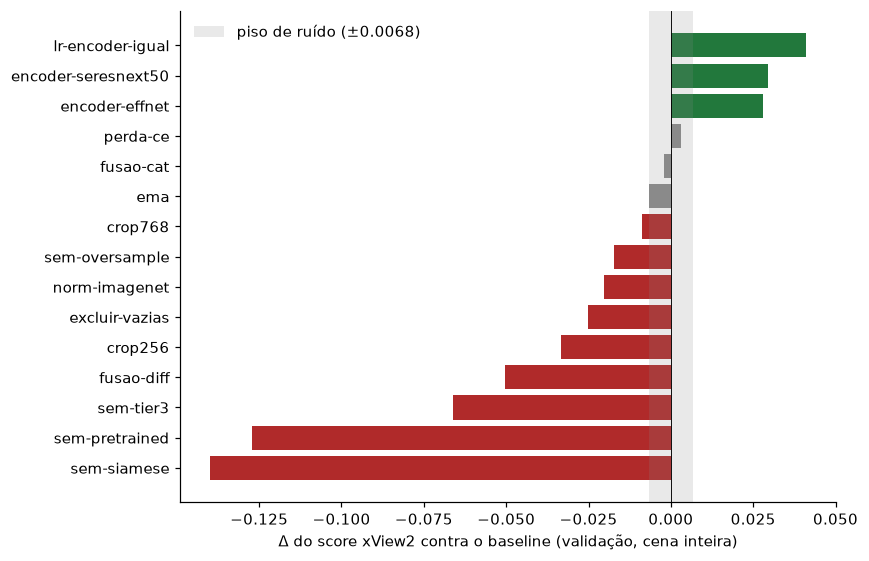

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.2))
cores = [VERDE if d > piso else (VERMELHO if d < -piso else CINZA) for d in abl.delta]
ax.barh(abl.nome.str.replace("abl-", ""), abl.delta, color=cores)
ax.axvspan(-piso, piso, color=CINZA, alpha=.18, lw=0, label=f"piso de ruído (±{piso:.4f})")
ax.axvline(0, color="k", lw=.6)
ax.invert_yaxis()
ax.set_xlabel("Δ do score xView2 contra o baseline (validação, cena inteira)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "ablacoes.png", dpi=160)
plt.show()

**Experimento 1: taxa de aprendizagem do encoder** (`abl-lr-encoder-igual`)
- *O que mudou:* `lr_encoder_mult` foi de 0,1 para 1,0. O encoder pré-treinado passa a aprender com 3e-4, a mesma taxa do decoder, em vez de 3e-5.
- *Hipótese:* frear o encoder é prática de *fine-tuning* longo. Com 20 épocas e um domínio distante do ImageNet (satélite visto de cima), o encoder precisa se adaptar, e o freio atrapalha.
- *Resultado:* +0,041 no score de validação, 6× o piso de ruído. É o maior ganho do estudo, e vem quase todo do termo de dano.
- *Decisão:* adotado. Este é o **modelo final**.

**Experimento 2: encoder menor** (`abl-encoder-effnet`)
- *O que mudou:* o encoder `resnet34` (25,5 M parâmetros no modelo todo) foi trocado por `efficientnet_b0` (6,2 M).
- *Hipótese:* se faltasse capacidade, o modelo menor perderia.
- *Resultado:* +0,028, empatado com o `seresnext50` (51 M). Capacidade não é o gargalo. Ressalva: este slot rodou com batch efetivo 16, e não 24.
- *Decisão:* não foi combinado com o experimento 1, porque não há um run que teste os dois juntos. Fica como próximo passo.

**Experimento 3: imagem pós** (`abl-sem-siamese`). Sem a imagem pós, a localização não muda e o score cai 0,14. Isso confirma que o sinal de dano vem da comparação entre as datas.

**Resultados negativos.** A diferença explícita `|Δ|` na fusão (`abl-fusao-cat`), o EMA e o termo focal (`abl-perda-ce`) ficaram todos dentro do ruído.

**Generalização para um desastre novo.** Os 5 folds agrupados medem o que o split oficial não mede:

In [6]:
grp = VAL[VAL.nome.str.startswith("base-grouped")].sort_values("nome")
ofi = VAL[VAL.nome == BASELINE].iloc[0]
tab = pd.DataFrame({
    "split oficial (hold)": [ofi.score_xview2, ofi.f1_loc, ofi.f1_dano_harmonico],
    "agrupado por desastre (media de 5 folds)": [grp.score_xview2.mean(), grp.f1_loc.mean(),
                                                 grp.f1_dano_harmonico.mean()],
    "desvio entre folds": [grp.score_xview2.std(), grp.f1_loc.std(), grp.f1_dano_harmonico.std()],
}, index=["score xView2", "F1 localizacao", "F1 dano (harmonica)"])
tab["queda"] = 1 - tab.iloc[:, 1] / tab.iloc[:, 0]
display(tab)

,split oficial (hold),agrupado por desastre (media de 5 folds),desvio entre folds,queda
score xView2,0.6583,0.4459,0.1200,0.3227
F1 localizacao,0.8455,0.8194,0.0236,0.0309
F1 dano (harmonica),0.5781,0.2859,0.1644,0.5055


## 4. Curvas de treinamento e validação

As curvas vêm do histórico por época (`results/history/*.jsonl`). Durante o treino, a validação usa o recorte central de 512 px de `hold`, que é mais barato. Os números das seções 3 e 5 vêm da reavaliação em cena inteira.

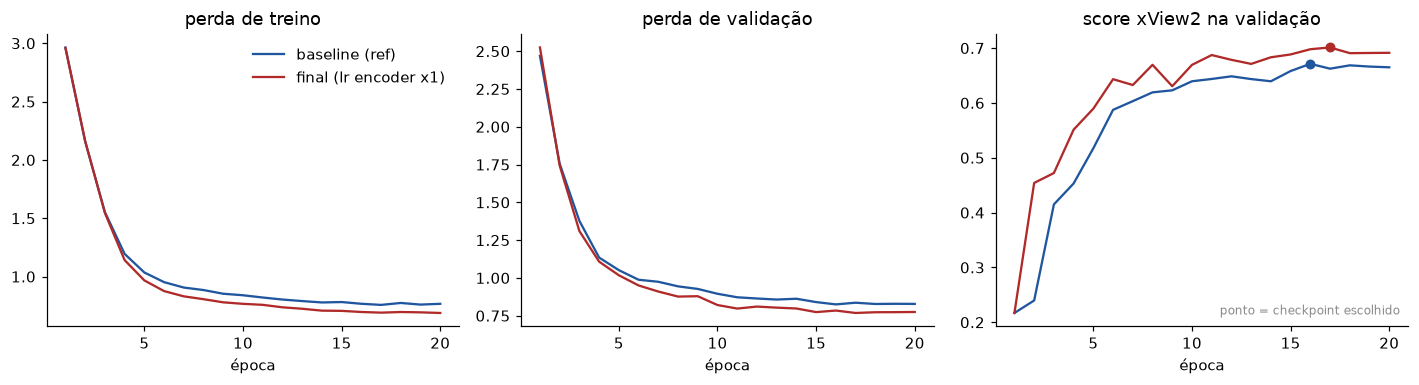

In [7]:
def historico(nome: str) -> pd.DataFrame:
    f = next((RES / "history").glob(f"{nome}-damage-*.jsonl"))
    return pd.DataFrame([json.loads(l) for l in f.read_text().splitlines() if l.strip()])

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for nome, cor, rot in [(BASELINE, AZUL, "baseline (ref)"), (FINAL, VERMELHO, "final (lr encoder x1)")]:
    h = historico(nome)
    ep = h.epoca + 1
    axs[0].plot(ep, h.perda_treino, color=cor, label=rot)
    axs[1].plot(ep, h.perda_val, color=cor, label=rot)
    axs[2].plot(ep, h.score_xview2, color=cor, label=rot)
    b = h.score_xview2.idxmax()
    axs[2].scatter(ep[b], h.score_xview2[b], color=cor, zorder=3, s=30)
for ax, t in zip(axs, ["perda de treino", "perda de validação", "score xView2 na validação"]):
    ax.set_title(t)
    ax.set_xlabel("época")
axs[0].legend(frameon=False)
axs[2].annotate("ponto = checkpoint escolhido", xy=(.98, .04), xycoords="axes fraction",
                ha="right", fontsize=8, color=CINZA)
fig.tight_layout()
fig.savefig(FIG / "curvas.png", dpi=160)
plt.show()

**Leitura.** Não há sobreajuste nas 20 épocas: as perdas de treino e de validação caem juntas até o fim. O score de validação se estabiliza nas últimas épocas, e o checkpoint escolhido foi o da época 16 no baseline e o da 17 no modelo final. O modelo final se separa do baseline já nas primeiras épocas, quando o encoder ainda está se adaptando, e mantém a vantagem até o fim. Com perda de validação ainda caindo, mais épocas provavelmente ajudariam os dois modelos.

## 5. Modelo final no conjunto de teste

Até aqui, toda escolha usou `hold`: a melhor época de cada run e o melhor run. Por isso o score de `hold` do modelo final é otimista por construção. O split `test` (933 cenas de 10 eventos) não entrou em nenhuma decisão, e é nele que o modelo final é medido. O baseline e as ablações são comparados na validação, onde a escolha foi feita.

Gerado com `python scripts/avaliar.py --checkpoints colheita --split teste --so abl-lr-encoder-igual`, que grava `results/avaliacao_teste.json` e a matriz de confusão de cada cena em `results/avaliacao_teste.por_cena.json`.

In [8]:
dup = pd.read_csv(RAIZ / "manifestos" / "duplicatas.csv")
tier = dict(zip(MANIFESTO.sample_id, MANIFESTO.tier))
VAZADAS = {a if tier.get(a) == "test" else b for a, b in zip(dup.a, dup.b)
           if "test" in (tier.get(a), tier.get(b)) and {tier.get(a), tier.get(b)} & {"tier1", "tier3"}}
print(f"cenas de teste com copia identica no treino destes runs: {len(VAZADAS)} de 933")


def soma(rid: str, cenas=None) -> np.ndarray:
    return sum(np.asarray(v) for k, v in POR_CENA[rid].items() if cenas is None or k in cenas)


linhas = {}
for nome in TESTE.nome:
    rid = run_id(nome, TESTE)
    limpas = set(POR_CENA[rid]) - VAZADAS
    v = VAL[VAL.nome == nome].iloc[0]
    t, tl = resumo(soma(rid)), resumo(soma(rid, limpas))
    linhas[nome] = {"validacao (hold)": v.score_xview2, "teste (933)": t["score_xview2"],
                    f"teste sem copias ({len(limpas)})": tl["score_xview2"],
                    "F1 loc (teste)": t["f1_loc"], "F1 dano (teste)": t["f1_dano_harmonico"]}
display(pd.DataFrame(linhas).T)

cenas de teste com copia identica no treino destes runs: 156 de 933


,validacao (hold),teste (933),teste sem copias (777),F1 loc (teste),F1 dano (teste)
abl-lr-encoder-igual,0.6994,0.69,0.6907,0.8559,0.6189


In [9]:
def por_classe(nome: str) -> pd.DataFrame:
    m = resumo(soma(run_id(nome, TESTE)))
    return pd.DataFrame({c: {"precisao": m[f"prec_{c}"], "revocacao": m[f"rec_{c}"],
                             "F1 = Dice": m[f"f1_{c}"], "IoU (Jaccard)": m[f"iou_{c}"]}
                         for c in CLASS_NAMES}).T

pf = por_classe(FINAL)
display(pf.round(4))
mf = resumo(soma(run_id(FINAL, TESTE)))
print(f"F1/Dice de localizacao (existe edificacao): {mf['f1_loc']:.4f}")
print(f"mIoU das 5 classes: {pf['IoU (Jaccard)'].mean():.4f}")

,precisao,revocacao,F1 = Dice,IoU (Jaccard)
background,0.9918,0.9912,0.9915,0.9831
no-damage,0.8224,0.8060,0.8141,0.6865
minor-damage,0.3990,0.4553,0.4253,0.2701
major-damage,0.5986,0.7100,0.6496,0.4810
destroyed,0.7642,0.7248,0.7440,0.5923


F1/Dice de localizacao (existe edificacao): 0.8559
mIoU das 5 classes: 0.6026


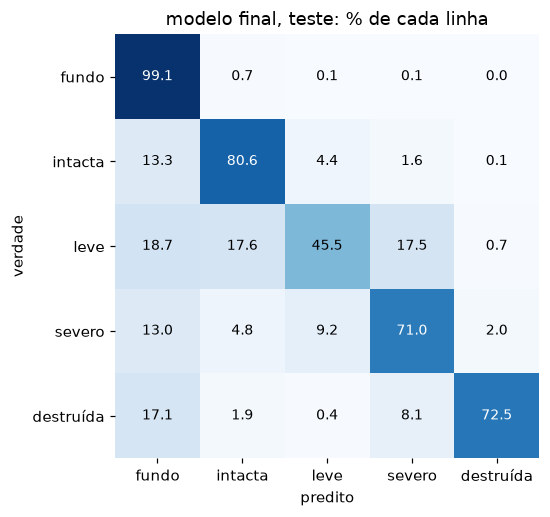

In [10]:
mat = soma(run_id(FINAL, TESTE)).reshape(5, 5).astype(float)
norm = mat / mat.sum(1, keepdims=True)
rot = ["fundo", "intacta", "leve", "severo", "destruída"]
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{100*norm[i, j]:.1f}", ha="center", va="center", fontsize=9,
                color="white" if norm[i, j] > .55 else "black")
ax.set_xticks(range(5), rot)
ax.set_yticks(range(5), rot)
ax.set_xlabel("predito")
ax.set_ylabel("verdade")
ax.set_title("modelo final, teste: % de cada linha")
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "confusao_teste.png", dpi=160)
plt.show()

**Leitura.**
- **Validação contra teste.** O modelo final faz **0,690** no teste, contra 0,699 em `hold`. A queda de 0,009 é o otimismo de ter escolhido época e modelo na validação, e fica perto do piso de ruído (0,0068). Não houve sobreajuste à validação.
- **Teste contra a validação do baseline.** Mesmo no teste, o modelo final fica 0,032 acima do score do baseline na validação (0,658). O ganho não se explica pelo otimismo da escolha, que custou só 0,009.
- **Cenas duplicadas.** Sem as 156 cenas com cópia no treino, o score do modelo final fica em 0,691. A duplicata `socal-fire`/`woolsey-fire` não inflou o teste.
- **Por classe.** Fundo e localização são o ponto forte: F1 0,856 para "existe edificação". Entre as severidades, `destruída` vai bem (F1 0,744, IoU 0,592) e `dano leve` é o gargalo (F1 0,425, IoU 0,270). Como o score usa média harmônica, é o dano leve que segura o número.
- **Média das classes.** O mIoU das 5 classes é 0,603.
- **Matriz de confusão.** Dos pixels de dano leve, só 45,5% recebem a classe certa: 17,6% viram intacta, 17,5% viram dano severo e 18,7% viram fundo.

## 6. Exemplos de previsões corretas e incorretas

As cenas vêm do teste, ficam fora das 156 cópias e têm pelo menos 40 mil pixels de edificação, com pelo menos 20% deles danificados. Elas são ordenadas pela fração de pixels de edificação encontrados que receberam a severidade certa, com uma cena por evento.

In [11]:
def tabela_cenas(rid: str) -> pd.DataFrame:
    out = []
    for cena, v in POR_CENA[rid].items():
        m = np.asarray(v).reshape(5, 5)
        edif = m[1:, :].sum()                      # pixels de edificacao na verdade
        achados = m[1:, 1:]
        tp_loc = achados.sum()
        fp_loc = m[0, 1:].sum()
        out.append({"cena": cena, "px_edificacao": edif,
                    "f1_loc": 2 * tp_loc / (2 * tp_loc + fp_loc + edif - tp_loc) if edif else np.nan,
                    "acerto_severidade": np.trace(achados) / tp_loc if tp_loc else np.nan,
                    "dano_real": m[2:, :].sum() / max(edif, 1)})
    df = pd.DataFrame(out)
    df["evento"] = df.cena.str.rsplit("_", n=1).str[0]
    return df

cenas = tabela_cenas(run_id(FINAL, TESTE))
cand = cenas[(cenas.px_edificacao > 40_000) & ~cenas.cena.isin(VAZADAS)]
acertos = (cand[cand.dano_real > .2].sort_values("acerto_severidade", ascending=False)
           .drop_duplicates("evento").head(3))
erros = (cand[cand.dano_real > .2].sort_values("acerto_severidade")
         .drop_duplicates("evento").head(3))
display(pd.concat({"acertos": acertos.set_index("cena"), "erros": erros.set_index("cena")}))

px_edificacao  f1_loc  acerto_severidade  dano_real               evento
        cena                                                                                                  
acertos santa-rosa-wildfire_00000366         116718  0.9124             1.0000     1.0000  santa-rosa-wildfire
        socal-fire_00001252                  131648  0.7686             0.9873     0.2761           socal-fire
        hurricane-harvey_00000468            109951  0.8643             0.9814     1.0000     hurricane-harvey
erros   midwest-flooding_00000287             52192  0.7272             0.0000     1.0000     midwest-flooding
        hurricane-michael_00000022            46926  0.8854             0.3595     0.5811    hurricane-michael
        hurricane-harvey_00000252             65450  0.8616             0.3761     0.2334     hurricane-harvey

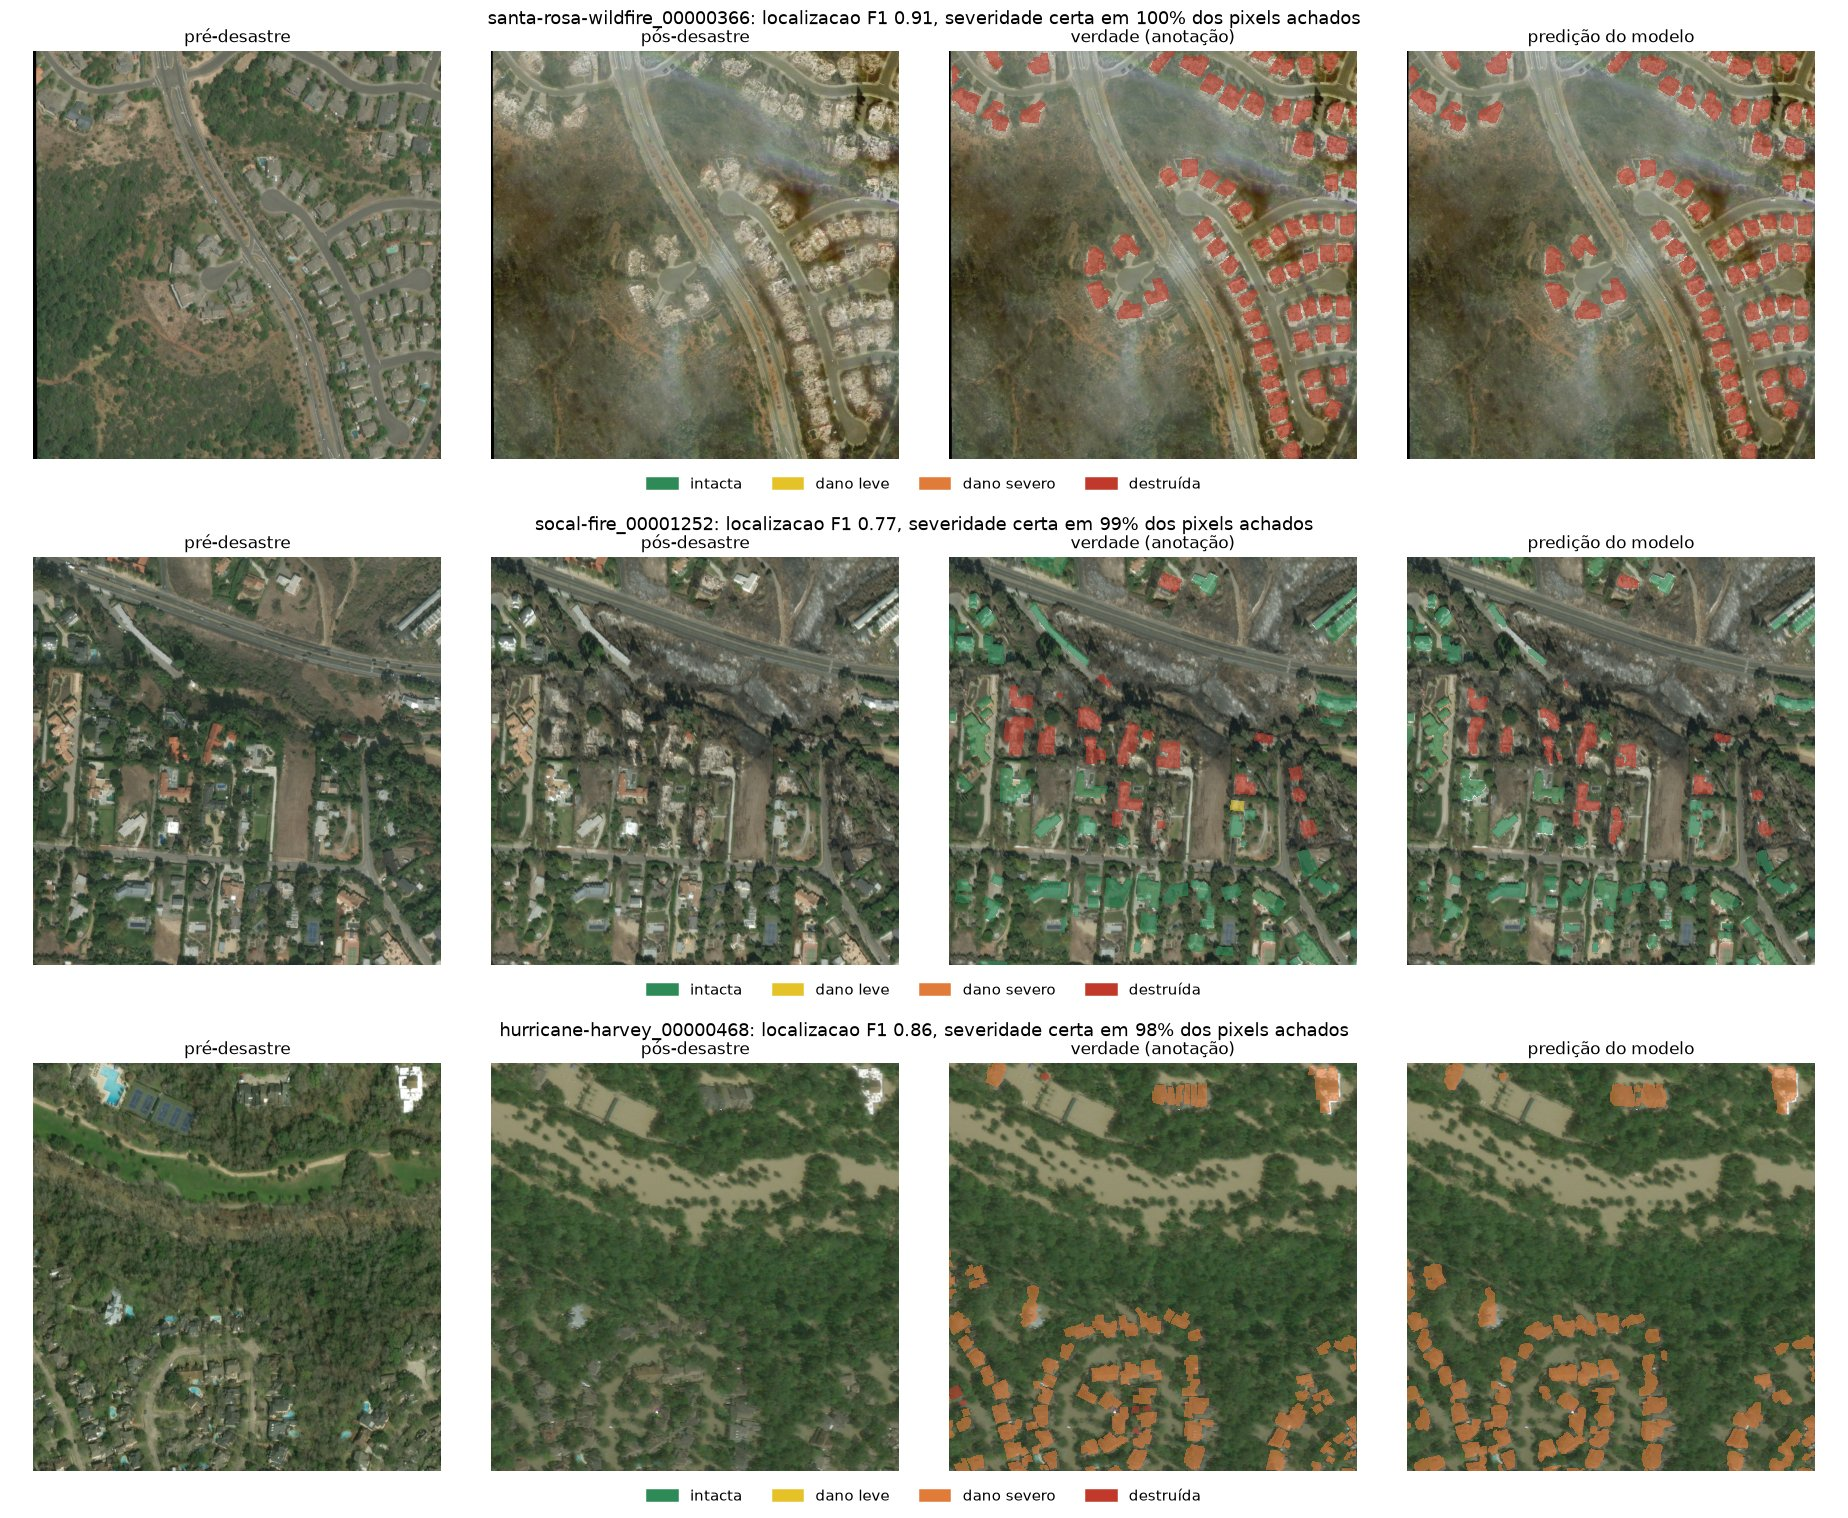

In [12]:
from PIL import Image as PILImage
from xbd.inferencia import carregar_modelo, figura, ler_imagem, ler_mascara, prever

DADOS = RAIZ / "data"
modelo_final, cfg_final, _ = carregar_modelo(RAIZ / "modelos" / "modelo_final.pt")


def painel(lista: pd.DataFrame, arquivo: str) -> None:
    if lista.empty:
        print("nenhuma cena atende ao criterio")
        return
    if not (DADOS / "images" / "test").exists():
        print(f"sem data/images/test: mostrando a figura salva {arquivo}")
        display(Img(FIG / arquivo))
        return
    imgs = []
    for _, r in lista.iterrows():
        pre = ler_imagem(DADOS / "images" / "test" / f"{r.cena}_pre.png")
        post = ler_imagem(DADOS / "images" / "test" / f"{r.cena}_post.png")
        alvo = ler_mascara(DADOS / "masks" / "test" / f"{r.cena}.png")
        res = prever(modelo_final, pre, post, cfg_final.norm)
        f = figura(pre, post, res, alvo,
                   titulo=f"{r.cena}: localizacao F1 {r.f1_loc:.2f}, "
                          f"severidade certa em {100*r.acerto_severidade:.0f}% dos pixels achados")
        f.canvas.draw()
        imgs.append(np.asarray(f.canvas.buffer_rgba())[..., :3])
        plt.close(f)
        PILImage.fromarray(imgs[-1]).save(FIG / arquivo.replace(".jpg", f"_{len(imgs)}.jpg"),
                                          quality=88)
    PILImage.fromarray(np.concatenate(imgs, 0)).save(FIG / arquivo, quality=85)
    display(Img(FIG / arquivo, width=1000))


painel(acertos, "acertos.jpg")

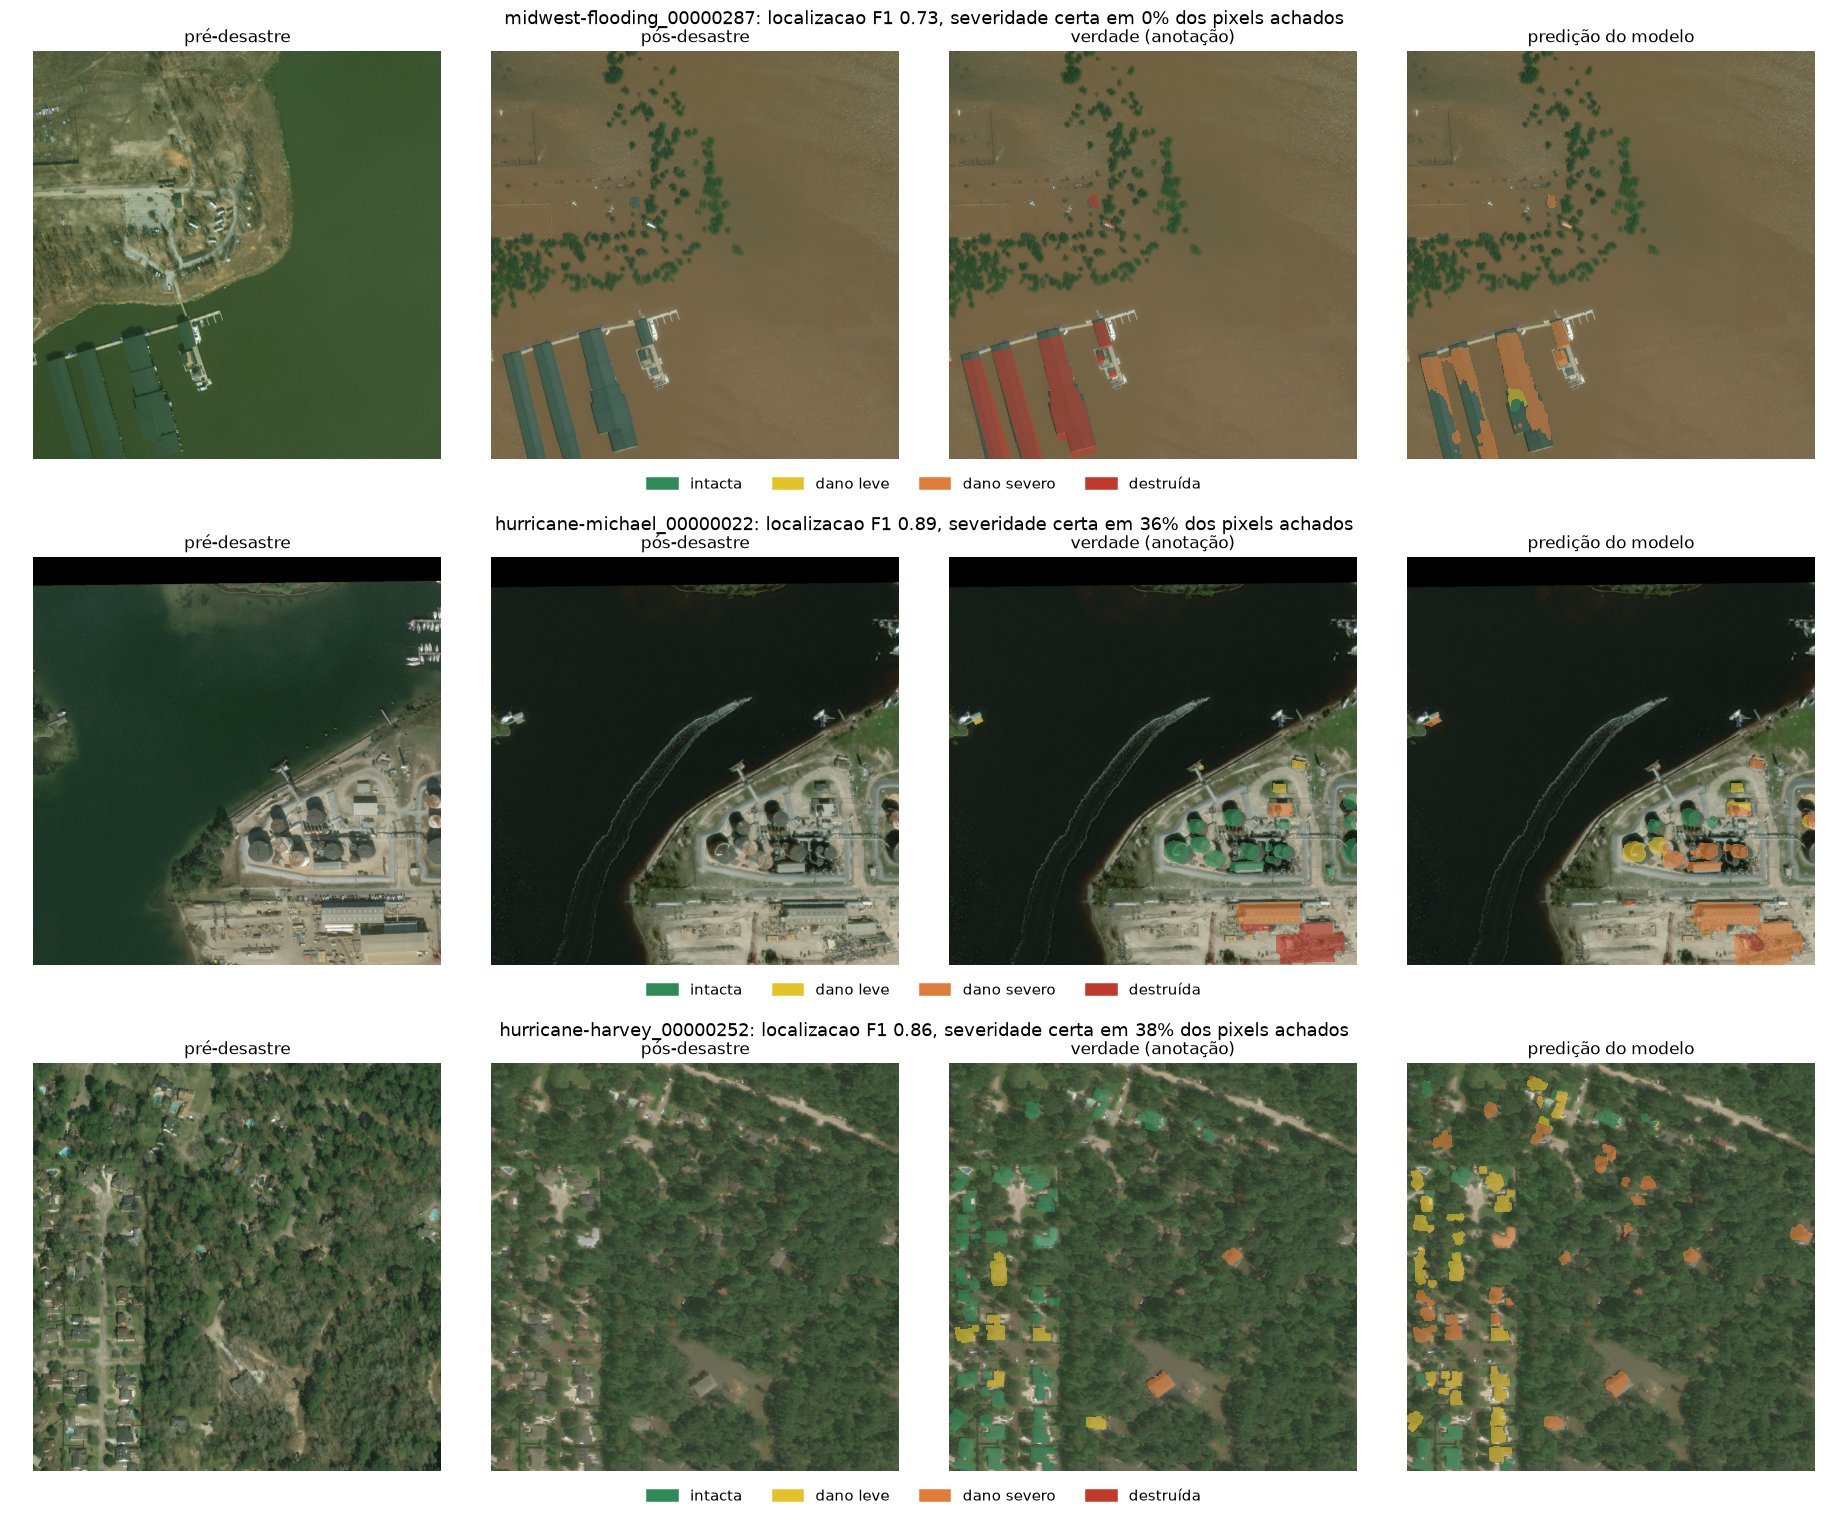

In [13]:
painel(erros, "erros.jpg")

**Acertos.**
- *santa-rosa-wildfire:* a destruição por incêndio é a mudança mais visível entre as datas, porque o lote queimado contrasta com o telhado do pré.
- *socal-fire:* o modelo separa casas destruídas de intactas na mesma rua.
- *hurricane-harvey_00000468:* as casas cercadas pela enchente recebem "dano severo", como na anotação.

**Erros.**
- *midwest-flooding:* galpões alagados, anotados como destruídos, saem como dano severo ou intactos. De cima, um telhado sob a água parece inteiro, e o que define o nível de dano (a água dentro do prédio) não aparece na imagem.
- *hurricane-michael_00000022:* área industrial, com tanques e galpões grandes, um tipo de estrutura raro no treino. O galpão destruído sai como dano severo.
- *hurricane-harvey_00000252:* casas sob a copa das árvores, anotadas como intactas ou com dano leve, saem com dano leve e severo. A diferença entre as datas (vegetação, estação, água no solo) é confundida com dano, e o modelo superestima a severidade.

## 7. Análise de erros

Primeiro, o modelo final no teste recortado por evento. Depois, por tamanho da área construída na cena.

In [14]:
tipo = MANIFESTO.set_index("sample_id").disaster_type.to_dict()
rid = run_id(FINAL, TESTE)
linhas = {}
for ev in sorted(cenas.evento.unique()):
    ids = {c for c in POR_CENA[rid] if c.rsplit("_", 1)[0] == ev}
    m = resumo(soma(rid, ids))
    linhas[ev] = {"tipo": tipo[next(iter(ids))], "cenas": len(ids),
                  "copias no treino": len(ids & VAZADAS),
                  "F1 loc": m["f1_loc"], **{f"F1 {c}": m[f"f1_{c}"] for c in DANO},
                  "score": m["score_xview2"]}
display(pd.DataFrame(linhas).T.sort_values("score"))

,tipo,cenas,copias no treino,F1 loc,F1 no-damage,F1 minor-damage,F1 major-damage,F1 destroyed,score
guatemala-volcano,volcano,5,0,0.5511,0.5744,0.0,0.0,0.9293,0.1653
mexico-earthquake,earthquake,38,0,0.8233,0.8177,0.0267,0.383,0.0,0.247
socal-fire,fire,307,156,0.838,0.8363,0.0,0.0253,0.722,0.2514
palu-tsunami,tsunami,42,0,0.8735,0.8631,0.0,0.2021,0.772,0.262
santa-rosa-wildfire,fire,74,0,0.878,0.8633,0.0,0.0,0.8705,0.2634
midwest-flooding,flooding,80,0,0.876,0.8651,0.0791,0.4426,0.0306,0.3202
hurricane-florence,flooding,108,0,0.8891,0.8721,0.077,0.7295,0.1051,0.3787
hurricane-harvey,flooding,108,0,0.8748,0.7644,0.3142,0.7382,0.0695,0.4008
hurricane-matthew,wind,73,0,0.7539,0.3085,0.6172,0.2363,0.4827,0.4769
hurricane-michael,wind,98,0,0.86,0.6863,0.4485,0.4675,0.4308,0.6017


In [15]:
cenas["faixa_tamanho"] = pd.cut(cenas.px_edificacao, [1, 10_000, 40_000, 100_000, 2e6],
                                labels=["<10k px", "10-40k", "40-100k", ">100k"], right=False)
display(cenas.groupby("faixa_tamanho", observed=True)
        .agg(cenas=("cena", "size"), f1_loc=("f1_loc", "median"),
             acerto_severidade=("acerto_severidade", "median")))

,cenas,f1_loc,acerto_severidade
faixa_tamanho,,,
<10k px,279,0.8287,0.9786
10-40k,158,0.8449,0.9615
40-100k,109,0.8624,0.9038
>100k,193,0.8700,0.9570


**Principais causas dos erros**

1. **A fronteira entre níveis é ambígua.** O dano leve vaza quase por igual para os dois lados: 17,6% vira intacta e 17,5% vira dano severo. Um erro simétrico assim aponta para incerteza na própria escala ordinal da anotação, e não para um viés do modelo. Precisão (0,40) e revocação (0,46) do dano leve são as duas baixas, então dar mais peso à classe não resolve.
2. **Prédios não encontrados.** Entre 13% e 19% dos pixels de cada classe com dano viram fundo. Um telhado destruído deixa de parecer edificação, e a métrica de dano paga junto esse erro de localização. A localização também é pior nas cenas com pouca área construída (mediana de F1 0,83 abaixo de 10 mil px, contra 0,87 acima de 100 mil).
3. **A aparência do dano depende do tipo de desastre.** O F1 de `destruída` vai de 0,87 (incêndio em Santa Rosa) a 0,03–0,11 nas enchentes (Florence, Harvey, Midwest). Em terremoto (México), o dano leve quase não é detectado (F1 0,03): o colapso visto de cima ainda parece um telhado. Isso é o mesmo que o split agrupado mostrou: num desastre não visto, o F1 de dano cai 51%.
4. **Rótulo com ruído.** Os polígonos do pós são cópias dos do pré, então qualquer desalinhamento entre as datas vira erro de rótulo. E a escala de 4 níveis é julgada por anotadores, com fronteiras subjetivas.

Na tabela por evento, o score xView2 fica baixo sempre que falta uma severidade, porque a média harmônica zera. Por isso, para comparar eventos, o que interessa são as colunas por classe.

## 8. Demonstração: imagem → pré-processamento → modelo → resultado

As 4 cenas de `amostras/` são do split `test` e nunca foram vistas no treino nem na escolha do modelo. O mesmo fluxo roda na linha de comando: `python scripts/demo.py`, ou `--pre a.png --post b.png` para qualquer par, inclusive o GeoTIFF original.

1. **imagem:** PNG `uint8`, ou GeoTIFF `int16` convertido como em `xbd/prep.py`;
2. **pré-processamento:** divisão por 255, normalização por canal com as constantes do treino e padding até múltiplo de 32;
3. **modelo:** U-Net siamesa → logits (5, H, W) → argmax por pixel;
4. **resultado:** máscara de severidade e contagem de edificações por classe. Cada componente conexo conta como uma edificação e recebe a classe da maioria dos seus pixels.

hurricane-matthew_00000105: 2.0s em CPU | edificacoes previstas: 5 intacta, 58 dano leve, 22 dano severo, 3 destruída


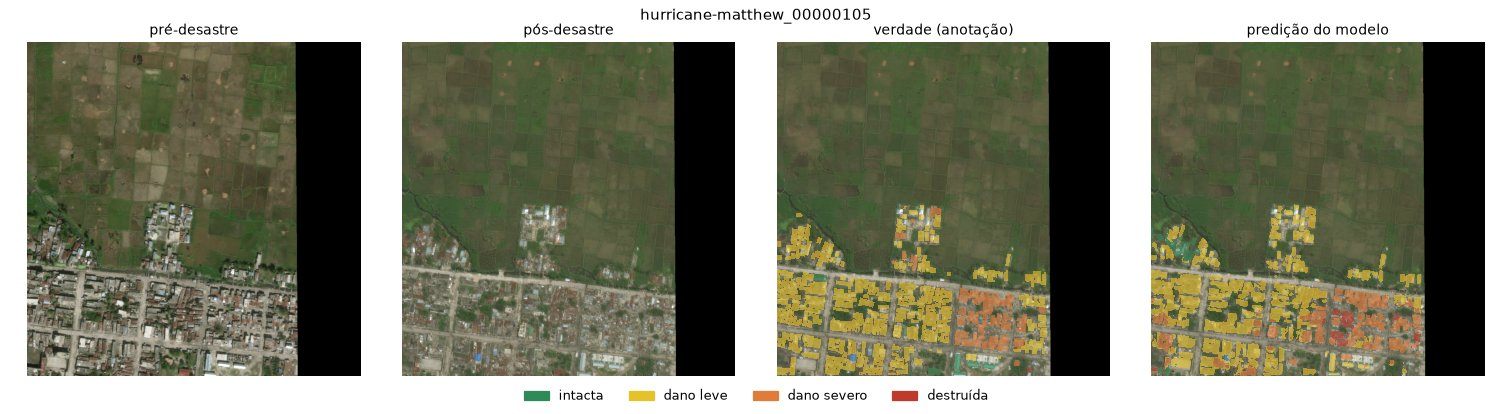

hurricane-michael_00000197: 2.0s em CPU | edificacoes previstas: 26 intacta, 27 dano leve, 25 dano severo, 8 destruída


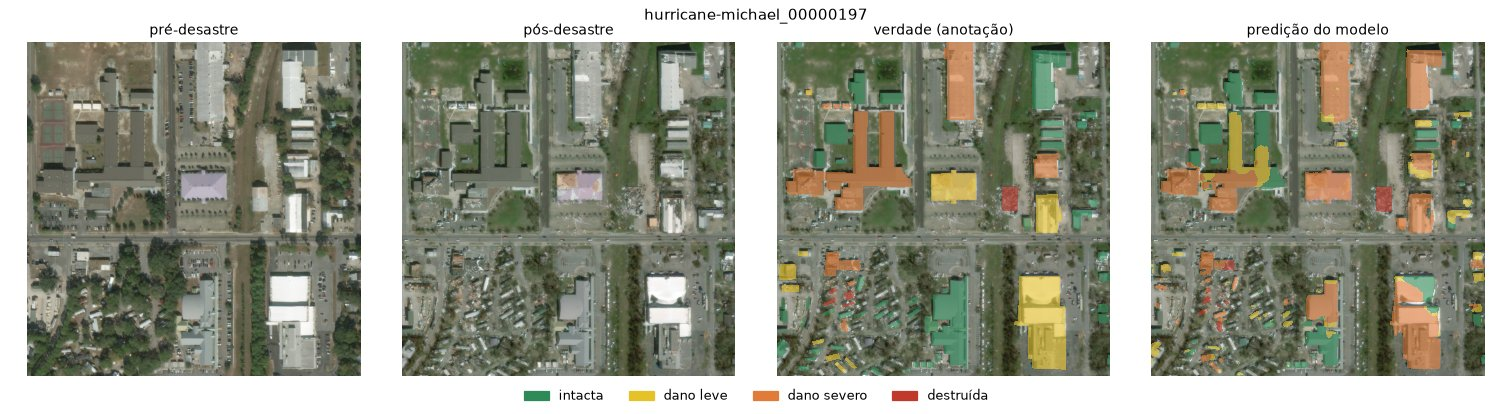

palu-tsunami_00000143: 2.0s em CPU | edificacoes previstas: 45 intacta, 0 dano leve, 3 dano severo, 31 destruída


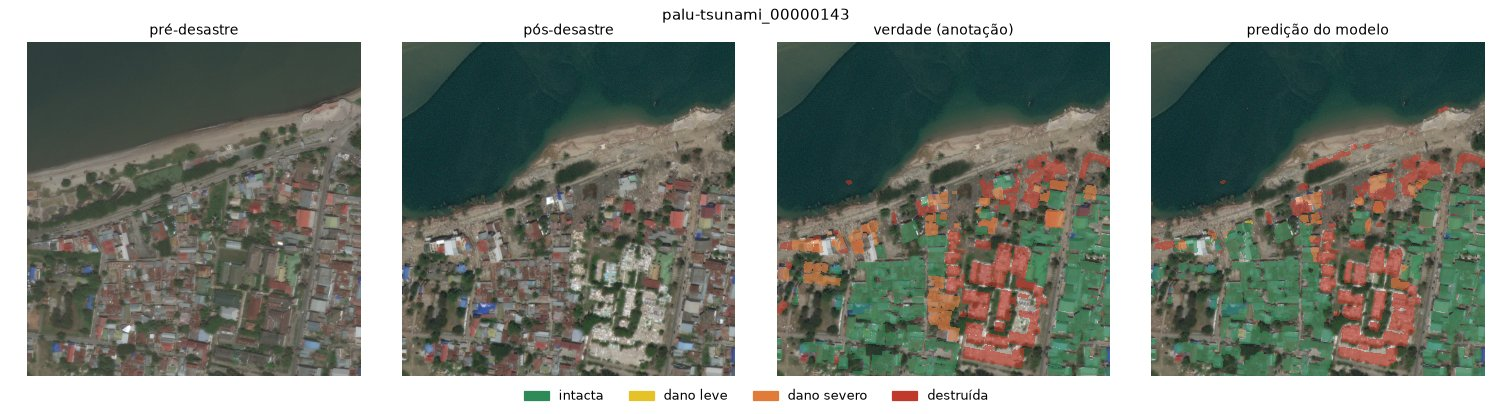

santa-rosa-wildfire_00000038: 2.0s em CPU | edificacoes previstas: 4 intacta, 0 dano leve, 0 dano severo, 104 destruída


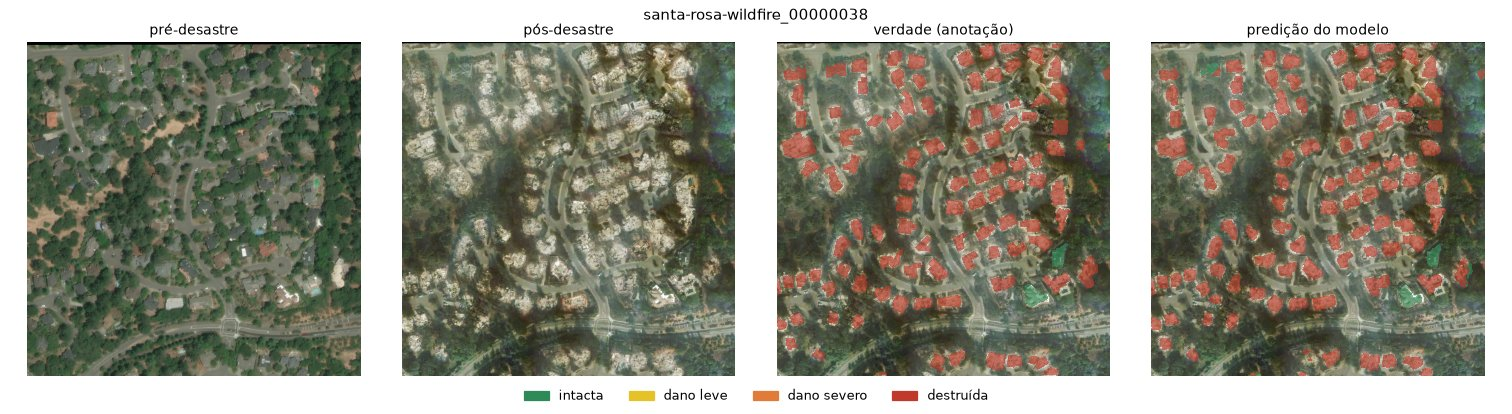

In [16]:
AMOSTRAS = RAIZ / "amostras"
for pre_f in sorted(AMOSTRAS.glob("*_pre.png")):
    cena = pre_f.name.removesuffix("_pre.png")
    pre = ler_imagem(pre_f)                                   # 1. imagem
    post = ler_imagem(AMOSTRAS / f"{cena}_post.png")
    t0 = time.time()
    res = prever(modelo_final, pre, post, cfg_final.norm)     # 2-3. pre-processamento + modelo
    dt = time.time() - t0
    alvo = ler_mascara(AMOSTRAS / f"{cena}_mask.png")
    print(f"{cena}: {dt:.1f}s em CPU | edificacoes previstas: "       # 4. resultado
          + ", ".join(f"{n} {k}" for k, n in res.edificacoes.items()))
    f = figura(pre, post, res, alvo, titulo=cena)
    buf = io.BytesIO()
    f.savefig(buf, format="jpeg", dpi=90, pil_kwargs={"quality": 85})
    plt.close(f)
    display(Img(data=buf.getvalue()))

## 9. Conclusão

**Resposta à pergunta.** Em parte.
- **Localizar edificações: sim.** O F1 de localização é 0,856 no teste e cai só 3% num desastre que o modelo não viu (split agrupado).
- **Graduar o dano: parcialmente.** No teste, o F1 de dano (média harmônica) é 0,619. É bom para `destruída` (0,744) e fraco para dano leve (0,425). Num desastre fora do treino, cai para 0,29.

Na prática, o modelo serve para triagem: separar áreas intactas de áreas com destruição evidente e priorizar onde olhar primeiro. Ele não substitui a avaliação humana dos níveis intermediários, e não deve ser aplicado a um tipo de desastre ausente do treino sem validação local.

**Os resultados foram satisfatórios?** Para o objetivo do trabalho, sim, com uma ressalva. O modelo final supera o baseline em +0,041 na validação, 6× o ruído, e no teste perde só 0,009 desse número (0,690), então a escolha resistiu ao teste. Ainda assim, fica abaixo dos 9 primeiros do ranking do xView2 (0,73 a 0,81), que usam ensembles, mais épocas e pós-processamento por edificação. Este é um único modelo, treinado por 20 épocas.

**O que os experimentos ensinaram.**
- **Medir o ruído antes de ler deltas.** Três sementes dão ±0,0068, e metade das ablações ficou dentro disso.
- **O maior ganho veio da otimização, não da arquitetura.** Não frear o encoder pré-treinado rendeu +0,041.
- **Componentes dados como úteis não se pagaram.** O termo `|Δ|` na fusão, a perda focal e o EMA ficaram dentro do ruído. Capacidade também não é o gargalo: o encoder de 6 M empata com o de 51 M.
- **O protocolo de avaliação pesa tanto quanto o modelo.** O split oficial superestima a generalização em 32%, e quase toda a diferença está no termo de dano.

**Limitações.**
- 20 épocas, com a perda de validação ainda caindo.
- Uma semente por ablação, e batch efetivo diferente em 4 slots.
- Os runs são anteriores à correção das duplicatas, embora o teste mostre que isso não mudou o resultado.
- Severidade fraca em desastres não vistos.
- Rótulos ordinais com ruído.

**Próximos passos.**
- Treinar a combinação `lr_encoder_mult = 1` + `efficientnet_b0` com o split corrigido e mais épocas.
- Atacar a *precisão* do dano leve.
- Votar a classe por edificação (polígono) em vez de por pixel.
- Validar sempre também no split agrupado, que é o número honesto para um desastre novo.